In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('logbook_assignment1.csv')

df_copy = df.copy()
df.info()


C:\Users\Wits student\AppData\Local\Temp\ipykernel_2768\3536676860.py:6: DtypeWarning: Columns (0: gallons, 1: mpg) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('logbook_assignment1.csv')


<class 'pandas.DataFrame'>
RangeIndex: 1174870 entries, 0 to 1174869
Data columns (total 9 columns):
 #   Column           Non-Null Count    Dtype 
---  ------           --------------    ----- 
 0   date_fueled      1125665 non-null  str   
 1   date_captured    1174870 non-null  str   
 2   odometer         1025716 non-null  str   
 3   gallons          1100660 non-null  object
 4   cost_per_gallon  1094110 non-null  str   
 5   total_spent      1100660 non-null  str   
 6   mpg              1100660 non-null  object
 7   miles            146274 non-null   str   
 8   user_url         1174870 non-null  str   
dtypes: object(2), str(7)
memory usage: 80.7+ MB


### Question 1.1 

#### 1.1.1 Identify what percentage of date fueled entries that are not proper dates.

In [2]:

df_copy['date_fueled'] = df_copy['date_fueled'].astype('str')


df_copy['date_fueled'] = df_copy['date_fueled'].replace('', np.nan)

row_count = len(df_copy)
missing_value_count = df_copy['date_fueled'].isna().sum()

date_conversion = pd.to_datetime(df_copy['date_fueled'], errors='coerce',format='%b %d %Y')

improper_data = df_copy['date_fueled'].notna() & date_conversion.isna() # Identify rows where 'date_fueled' is not NaN but conversion to datetime failed
improper_data_count = improper_data.sum() 

percentage = (improper_data_count/(row_count - missing_value_count)) * 100
print(f"Percentage of improper data in 'date_fueled' column: {percentage:.2f}%")
print(date_conversion.head(15))


Percentage of improper data in 'date_fueled' column: 7.82%
0           NaT
1    2012-11-07
2    2012-09-22
3    2019-05-04
4    2022-02-15
5    2021-10-23
6    2021-11-20
7    2022-01-20
8           NaT
9           NaT
10   2020-11-15
11   2022-01-14
12   2021-11-22
13   2021-03-28
14   2021-11-17
Name: date_fueled, dtype: datetime64[us]


#### 1.1.2 and 1.1.3 : Fill missing values in 'date_fueled' with corresponding values from 'date_captured' and convert both columns to datetime format.

In [3]:

df_copy['date_captured'] = pd.to_datetime(df_copy['date_captured'], errors='coerce', format='%b %d %Y')
date_conversion = pd.to_datetime(df_copy['date_fueled'], errors='coerce', format='%b %d %Y')
df_copy['date_fueled'] = date_conversion.fillna(df_copy['date_captured'])

print(df_copy['date_fueled'].head(15))



0    2022-04-07
1    2012-11-07
2    2012-09-22
3    2019-05-04
4    2022-02-15
5    2021-10-23
6    2021-11-20
7    2022-01-20
8    2018-04-16
9    2020-11-29
10   2020-11-15
11   2022-01-14
12   2021-11-22
13   2021-03-28
14   2021-11-17
Name: date_fueled, dtype: datetime64[us]


#### 1.1.4 : Removing rows with past dates (before 2005) and future dates (after 2026)

In [4]:

start_date = pd.to_datetime('2005-01-01')
ending_date = pd.to_datetime('2026-12-31')

dates_in_range = (df_copy['date_fueled'] >= start_date) & (df_copy['date_fueled'] <= ending_date)

dates_in_range_copy = df_copy[dates_in_range].copy()

dates_in_range_copy[['date_fueled', 'date_captured']].head(15)

,date_fueled,date_captured
0,2022-04-07,2022-04-07
1,2012-11-07,2016-08-30
2,2012-09-22,2012-09-28
3,2019-05-04,2019-05-04
4,2022-02-15,2022-02-15
5,2021-10-23,2021-10-23
6,2021-11-20,2021-12-12
7,2022-01-20,2022-01-20
8,2018-04-16,2018-04-16
9,2020-11-29,2020-11-29


#### 1.1.5 : Visualizing the distribution of fueling dates using a histogram 

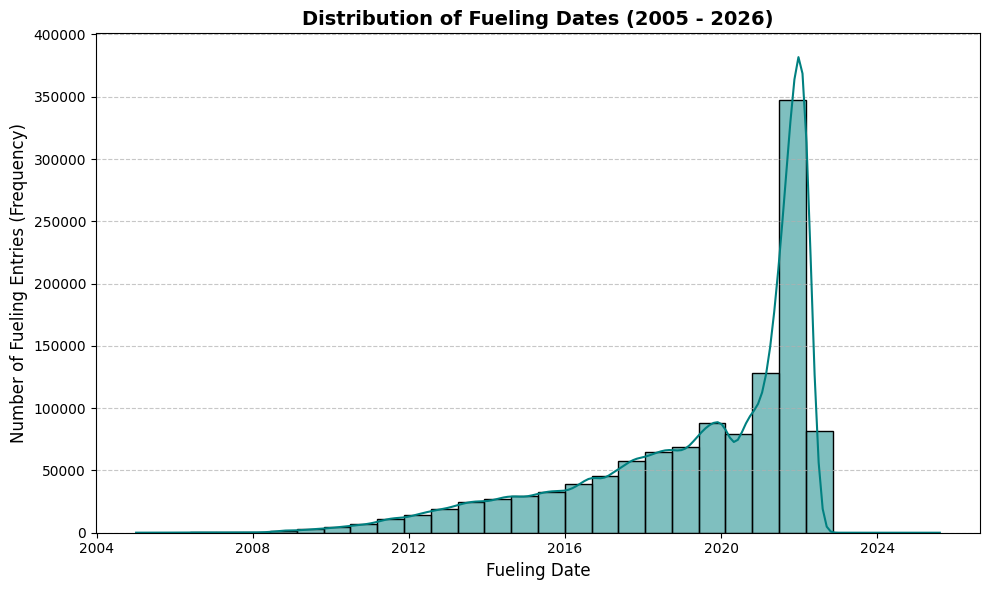

In [5]:

plt.figure(figsize=(10, 6))

sns.histplot(data=dates_in_range_copy, x='date_fueled', kde=True, color='teal', bins=30)

plt.title("Distribution of Fueling Dates (2005 - 2026)", fontsize=14, fontweight='bold')
plt.xlabel("Fueling Date", fontsize=12)
plt.ylabel("Number of Fueling Entries (Frequency)", fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Display the plot window
plt.tight_layout()
plt.show() 

### Question 1.2

#### 1.2.1 and 1.2.3 : Identify what percentage of gallons, miles, and odometer entries are missing and convert the columns to float64 data type.

In [6]:

for col in ['odometer', 'gallons', 'miles', 'mpg']:
    dates_in_range_copy[col] = dates_in_range_copy[col].astype('str').str.strip().str.replace(',','')

    dates_in_range_copy[col] = dates_in_range_copy[col].replace('', np.nan)

    dates_in_range_copy[col] = dates_in_range_copy[col].astype('float64')

count = len(dates_in_range_copy)
odo_missing = dates_in_range_copy['odometer'].isna().sum()
gallons_missing = dates_in_range_copy['gallons'].isna().sum()   
miles_missing = dates_in_range_copy['miles'].isna().sum()   

print(f"Percentage of missing values in 'odometer' column: {(odo_missing / count) * 100:.2f}%")
print(f"Percentage of missing values in 'gallons' column: {(gallons_missing / count) * 100:.2f}%")
print(f"Percentage of missing values in 'miles' column: {(miles_missing / count) * 100:.2f}%")

Percentage of missing values in 'odometer' column: 12.69%
Percentage of missing values in 'gallons' column: 6.32%
Percentage of missing values in 'miles' column: 87.55%


#### 1.2.2 : Calculating the miles, gallons and mpg columns

In [7]:
 
miles_missing = dates_in_range_copy['miles'].isna()
dates_in_range_copy.loc[miles_missing, 'miles'] = dates_in_range_copy['mpg'] * dates_in_range_copy['gallons']

gallons_missing = dates_in_range_copy['gallons'].isna()
dates_in_range_copy.loc[gallons_missing, 'gallons'] = dates_in_range_copy['miles'] / dates_in_range_copy['mpg']

mpg_missing = dates_in_range_copy['mpg'].isna()
dates_in_range_copy.loc[mpg_missing, 'mpg'] = dates_in_range_copy['miles'] / dates_in_range_copy['gallons']

for col in ['odometer', 'gallons', 'miles', 'mpg']:
    dates_in_range_copy[col] = dates_in_range_copy[col].round(4)


# Delete rows with missing values in 'miles', 'gallons', or 'mpg' columns
dates_in_range_copy = dates_in_range_copy.dropna(subset=['miles', 'gallons', 'mpg'], how='any')
dates_in_range_copy = dates_in_range_copy.reset_index(drop=True)



#### 1.2.4 : Plotting the distribution of miles, gallons, mpg, and odometer readings using histograms

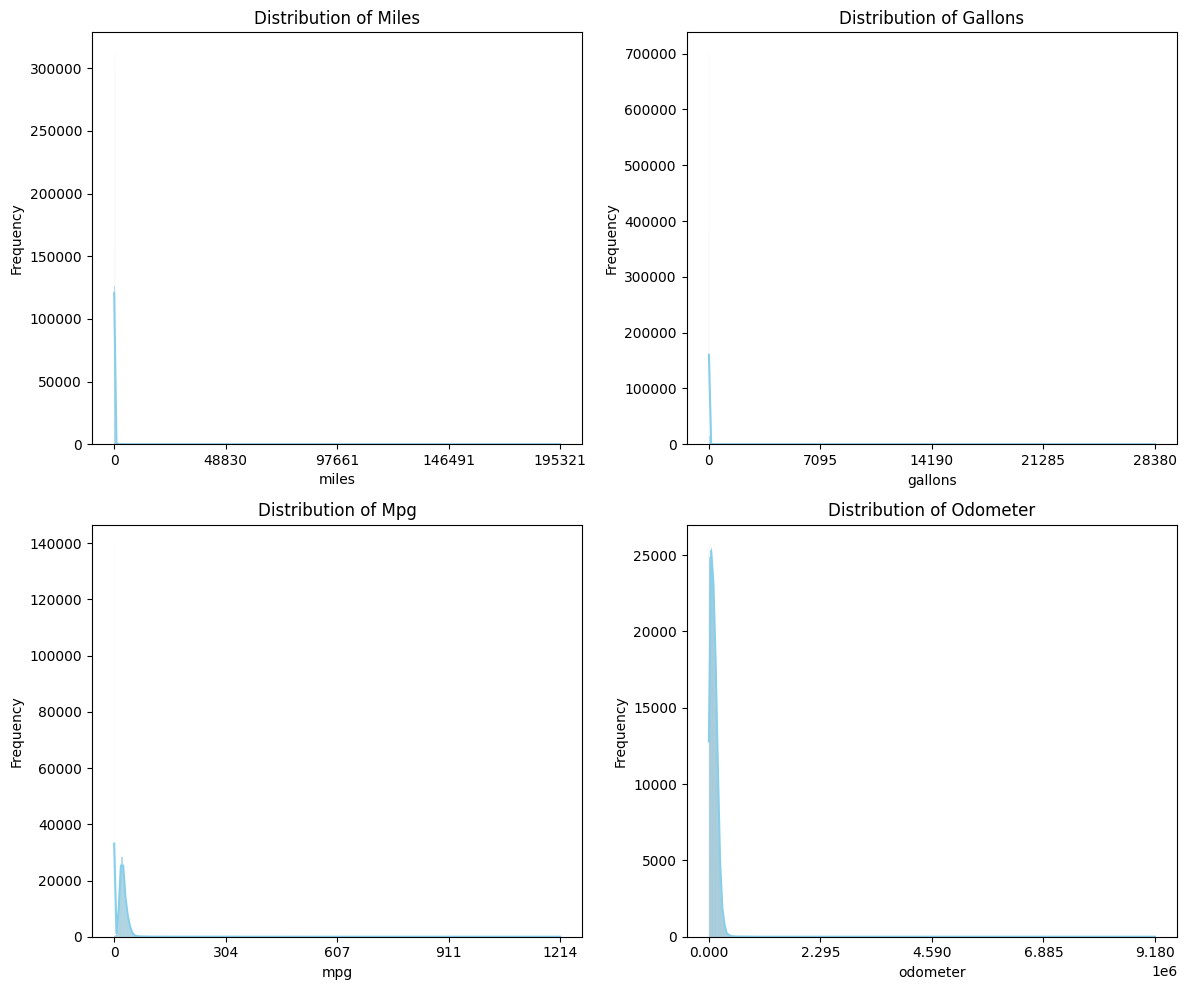

In [8]:

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
columns = ['miles', 'gallons', 'mpg', 'odometer']

for ax, col in zip(axes.flatten(), columns):
    sns.histplot(dates_in_range_copy[col].dropna(), kde=True, ax=ax, color='skyblue')
    ax.set_title(f'Distribution of {col.capitalize()}')
    ax.set_xlabel(col)
    col_min = dates_in_range_copy[col].min()
    col_max = dates_in_range_copy[col].max()
    ax.set_xticks(np.linspace(col_min, col_max, 5))
    ax.set_ylabel('Frequency')

plt.tight_layout()
plt.show()

#### 1.2.6 : Generating descriptive statistics for the 'miles', 'gallons', 'mpg', and 'odometer' columns, including the most frequent (mode) value.

In [9]:

columns = ['miles', 'gallons', 'mpg', 'odometer']
stats_desc = dates_in_range_copy[columns].describe()


modes = dates_in_range_copy[columns].mode().iloc[0] # Adding mode manually
stats_desc.loc['most_frequent'] = modes

print(stats_desc)

                      miles       gallons           mpg      odometer
count          1.100122e+06  1.100122e+06  1.100122e+06  9.524600e+05
mean           2.694538e+02  1.279740e+01  2.216306e+01  1.022979e+05
std            7.257657e+02  7.448303e+01  1.574439e+01  7.701520e+04
min            0.000000e+00  0.000000e+00  0.000000e+00  0.000000e+00
25%            1.814000e+02  8.990000e+00  1.560000e+01  4.488100e+04
50%            2.670483e+02  1.195400e+01  2.180000e+01  9.075100e+04
75%            3.427648e+02  1.493900e+01  2.850000e+01  1.459520e+05
max            1.953212e+05  2.838000e+04  1.214300e+03  9.180140e+06
most_frequent  0.000000e+00  1.056700e+01  0.000000e+00  1.000000e+00


### Question 2

#### 2.1 : Creating the currency column by extracting the currency symbol from 'cost_per_gallon' and 'total_spent' columns

In [10]:

currency = dates_in_range_copy['cost_per_gallon'].astype(str).str.extract(r"^([^\d,\s]+(?:\.)?)")

extracted_from_total = dates_in_range_copy['total_spent'].astype(str).str.extract(r"^([^\d,\s]+(?:\.)?)")

final_currency = currency.fillna(extracted_from_total)

placement_index = dates_in_range_copy.columns.get_loc("gallons") + 1
dates_in_range_copy.insert(placement_index, "currency", final_currency)


#### 2.2 : Removing any non-numeric characters from 'cost_per_gallon' and 'total_spent' columns, convert to numeric, and round to 4 decimal places

In [11]:

for col in ['cost_per_gallon', 'total_spent']:
    dates_in_range_copy[col] = dates_in_range_copy[col].astype(str).str.replace(r'[^\d.]', '', regex=True)

    dates_in_range_copy[col] = pd.to_numeric(dates_in_range_copy[col], errors='coerce')

    dates_in_range_copy[col] = dates_in_range_copy[col].round(4)

#Fill in the total_spent and cost_per_gallon columns with the appropriate calculations if they are missing
total_spent_missing = dates_in_range_copy['total_spent'].isna()
dates_in_range_copy.loc[total_spent_missing, 'total_spent'] = dates_in_range_copy['cost_per_gallon'] * dates_in_range_copy['gallons']

cost_per_gallon_missing = dates_in_range_copy['cost_per_gallon'].isna()
dates_in_range_copy.loc[cost_per_gallon_missing, 'cost_per_gallon'] = dates_in_range_copy['total_spent'] / dates_in_range_copy['gallons']

# Dropping rows where both 'cost_per_gallon' and 'total_spent' are null
dates_in_range_copy = dates_in_range_copy.dropna(subset=['cost_per_gallon', 'total_spent'], how='all')
dates_in_range_copy = dates_in_range_copy.reset_index(drop=True)

# Asuming that if 'cost_per_gallon' is missing, it should be filled with 0.0. 
missing_cost = dates_in_range_copy['cost_per_gallon'].isna()
dates_in_range_copy.loc[missing_cost, 'cost_per_gallon'] = 0.0



#### 2.3 : Extracting car name, model, year, and user_id from 'user_url' column using regex

In [12]:

pattern = r'/(?P<make>[a-zA-Z0-9-_]+)/(?P<model>[a-zA-Z0-9-_]+)/(?P<year>\d{4})/(?P<user_id>\d+)'

data = dates_in_range_copy['user_url'].str.extract(pattern)
dates_in_range_copy[['car_name', 'model', 'year', 'user_id']] = data

extracted_user_ids = dates_in_range_copy['user_url'].astype(str).str.rstrip('/').str.extract(r'(\d+)$')[0]
dates_in_range_copy['user_id'] = dates_in_range_copy['user_id'].fillna(extracted_user_ids) # Fill in the missing user_id values with the extracted user_ids from the 'user_url' column

# Checking if the regex extraction worked by selecting a sample user_id and displaying all rows for that user_id
sample_user = dates_in_range_copy['user_id'].dropna().iloc[1546]

user_history = dates_in_range_copy[dates_in_range_copy['user_id'] == sample_user]
print(f"--- Complete Rows for User ID: {sample_user} ---")
print(user_history)

--- Complete Rows for User ID: 399632 ---
       date_fueled date_captured  odometer  gallons currency  cost_per_gallon  \
1546    2020-11-21    2020-11-21  135836.0   15.109        $            1.949   
144845  2020-12-29    2020-12-29  136974.0   12.588        $            2.119   
168866  2021-01-03    2021-01-03  137154.0   12.053        $            2.049   
287220  2021-05-02    2021-05-02  140483.0   14.380        $            2.749   
365279  2021-01-18    2021-01-18  137714.0   11.961        $            2.249   
479231  2021-06-05    2021-06-05  140690.0   14.451        $            2.849   
556441  2021-01-09    2021-01-09  137351.0   13.398        $            2.099   
657263  2021-03-07    2021-03-07  139214.0   15.162        $            2.749   
729598  2021-02-07    2021-02-07  138393.0   12.748        $            2.409   
775257  2020-12-17    2020-12-17  136630.0   14.795        $            2.049   
893432  2020-12-04    2020-12-04  136226.0   14.487        $       

#### 2.4 : Converting miles to kilometers, gallons to liters, and calculate liters per 100 km

In [13]:

dates_in_range_copy['km_driven'] = (dates_in_range_copy['miles'] * 1.60934).round(4)

dates_in_range_copy['litres_filled'] = (dates_in_range_copy['gallons'] * 3.78541).round(4) # Because the currency that is being used the most is USD we assume that the gallons are US gallons. 

dates_in_range_copy['litres_per_100km'] = ((dates_in_range_copy['litres_filled'] / dates_in_range_copy['km_driven']) * 100).round(4)
dates_in_range_copy['litres_per_100km'] = dates_in_range_copy['litres_per_100km'].replace([np.inf, -np.inf], np.nan)  # Replace infinite values with NaN

### Question 3

#### 3.1 : Visualizing the number of unique users per country (using currency as a proxy for country) using a bar plot

C:\Users\Wits student\AppData\Local\Temp\ipykernel_2768\1003487738.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=users_per_country.values, y=users_per_country.index, palette='viridis')


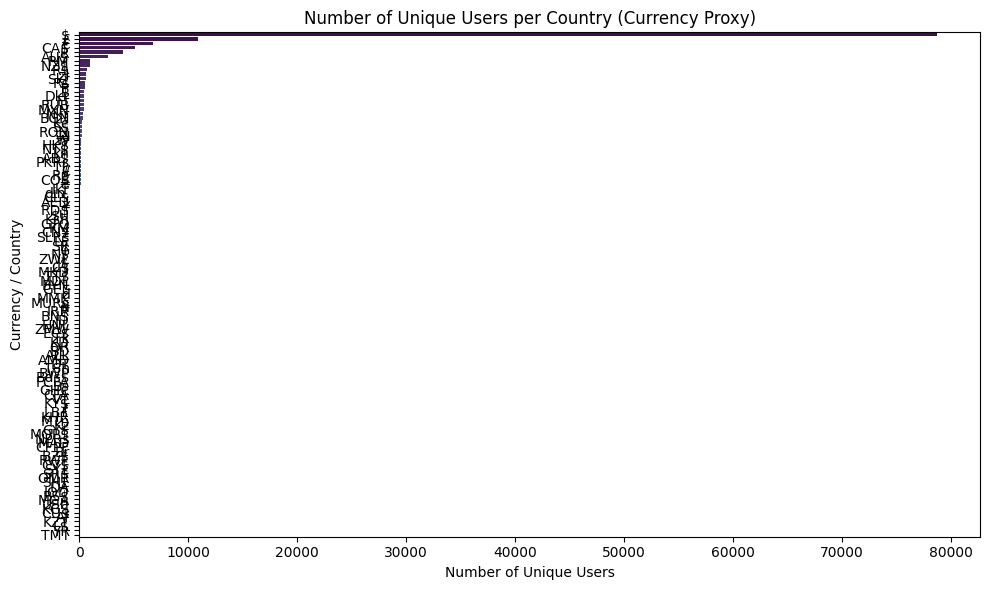

In [14]:

# Group by currency and count unique users
users_per_country = dates_in_range_copy.groupby('currency')['user_id'].nunique().sort_values(ascending=False)

# Plotting
plt.figure(figsize=(10, 6))
sns.barplot(x=users_per_country.values, y=users_per_country.index, palette='viridis')
plt.title('Number of Unique Users per Country (Currency Proxy)')
plt.xlabel('Number of Unique Users')
plt.ylabel('Currency / Country')
plt.tight_layout()
plt.show()

#### 3.2 : Visualizing the number of unique users per day using a bar plot

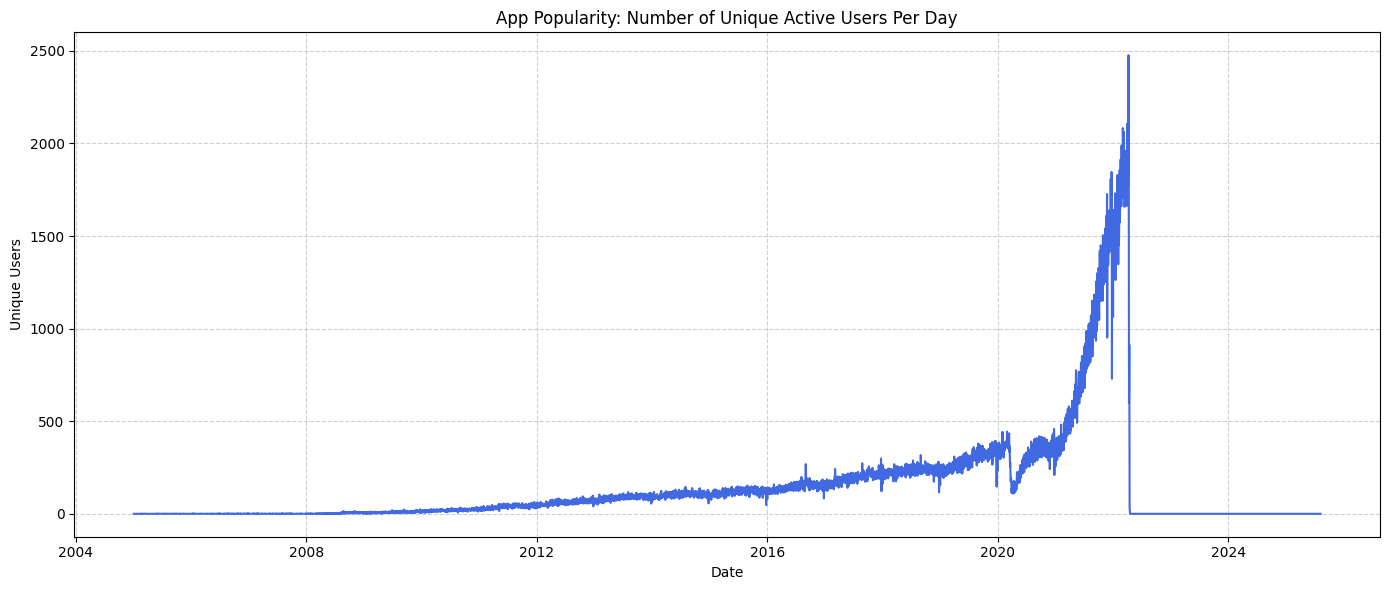

In [15]:

# Group by date string (YYYY-MM-DD) and count unique active users
daily_active_users = dates_in_range_copy.groupby(dates_in_range_copy['date_fueled'].dt.date)['user_id'].nunique()

plt.figure(figsize=(14, 6))
plt.plot(daily_active_users.index, daily_active_users.values, color='royalblue', linewidth=1.5)
plt.title('App Popularity: Number of Unique Active Users Per Day')
plt.xlabel('Date')
plt.ylabel('Unique Users')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

### 3.3 : Calculate the age of the vehicle at the time of refuelling and plot the distribution of vehicle ages per country using a boxplot

C:\Users\Wits student\AppData\Local\Temp\ipykernel_2768\191684663.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=raw_age_df, x='currency', y='vehicle_age_at_refuel', palette='Set3')


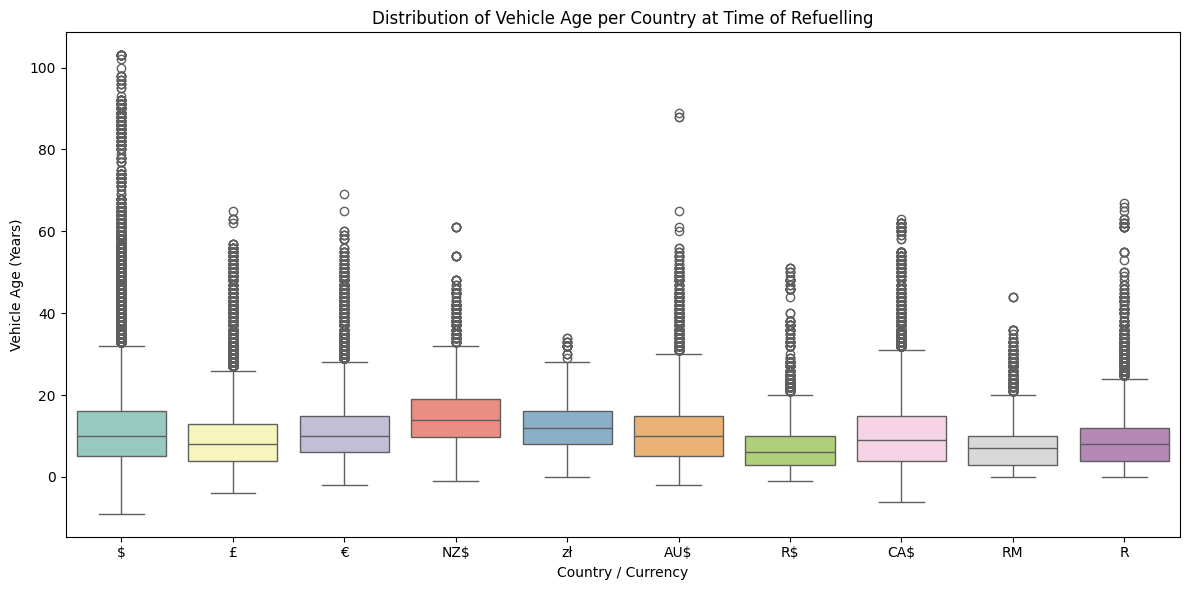

In [16]:

dates_in_range_copy['fueled_year'] = dates_in_range_copy['date_fueled'].dt.year
dates_in_range_copy['year'] = pd.to_numeric(dates_in_range_copy['year'], errors='coerce')


dates_in_range_copy['vehicle_age_at_refuel'] = dates_in_range_copy['fueled_year'] - dates_in_range_copy['year']

# Keeping the top 10 most common countries so the text labels are readable
top_currencies = dates_in_range_copy['currency'].value_counts().head(10).index
raw_age_df = dates_in_range_copy[dates_in_range_copy['currency'].isin(top_currencies)]


plt.figure(figsize=(12, 6))
sns.boxplot(data=raw_age_df, x='currency', y='vehicle_age_at_refuel', palette='Set3')
plt.title('Distribution of Vehicle Age per Country at Time of Refuelling')
plt.xlabel('Country / Currency')
plt.ylabel('Vehicle Age (Years)')
plt.tight_layout()
plt.show()

#### 3.4 Visualizing the distribution of vehicle ages at the time of refuelling using a histogram

In [17]:

unique_profiles = dates_in_range_copy.drop_duplicates(subset=['user_id']) # Dropping duplicate rows for the same user so we count unique user profiles


print("--- Top 5 Most Popular Vehicle Makes ---")
print(unique_profiles['car_name'].value_counts().head(5))

# Create a combined Make + Model column to find specific popular vehicles (e.g., VW Golf, Toyota Hilux)
unique_profiles['model'] = unique_profiles['car_name'].astype(str) + " " + unique_profiles['model'].astype(str)

print("\n--- Top 10 Most Popular Vehicle Models ---")
print(unique_profiles['model'].value_counts().head(10))

--- Top 5 Most Popular Vehicle Makes ---
car_name
ford          14352
toyota        13409
bmw           11006
nissan         8817
volkswagen     7648
Name: count, dtype: int64

--- Top 10 Most Popular Vehicle Models ---
model
ford mustang           814
ford f-150             775
toyota land_cruiser    747
honda civic            742
toyota corolla         734
toyota 4runner         733
ford ranger            712
honda accord           703
toyota camry           702
volkswagen jetta       678
Name: count, dtype: int64


## Question 4.1

#### 4.1.1: Find the top 5 currencies by transaction count 

In [18]:

top_5_currencies = dates_in_range_copy['currency'].value_counts().head(5).index.tolist()
print(f"Top 5 currencies by transactions: {top_5_currencies}")

Top 5 currencies by transactions: ['$', '£', '€', 'CA$', 'R']


### 4.1.2: Removing outliers

In [19]:


initial_count = len(dates_in_range_copy)

# Filter the dataframe to only keep the top 5 currencies for this analysis
df_top5 = dates_in_range_copy[dates_in_range_copy['currency'].isin(top_5_currencies)].copy()
df_cleaned_master = pd.DataFrame()



for curr in top_5_currencies:
    mask = df_top5['currency'] == curr
    curr_df = df_top5[mask]
    
    
    volume_filter = (curr_df['litres_filled'] > 5) & (curr_df['litres_filled'] < 150)
    
    # Currency-specific financial logic based on 'total_spend' and 'cost_per_gallon'
    if curr == 'ZAR' or curr == 'R':
        financial_filter = (curr_df['total_spent'].between(100, 3500)) & (curr_df['cost_per_gallon'].between(40, 150))
    elif curr == '$' or curr == 'USD': 
        financial_filter = (curr_df['total_spent'].between(10, 150)) & (curr_df['cost_per_gallon'].between(2.0, 9.0))
    elif curr == '£' or curr == 'GBP': 
        financial_filter = (curr_df['total_spent'].between(10, 150)) & (curr_df['cost_per_gallon'].between(4.0, 14.0))
    elif curr == '€' or curr == 'EUR':
        financial_filter = (curr_df['total_spent'].between(10, 150)) & (curr_df['cost_per_gallon'].between(4.0, 14.0))
    else: 
       
        financial_filter = (curr_df['total_spent'] > 0) & (curr_df['cost_per_gallon'] > 0)
        
    # Applying filters to the current currency subset
    clean_curr_df = curr_df[volume_filter & financial_filter]
    df_cleaned_master = pd.concat([df_cleaned_master, clean_curr_df], axis=0)
    df_cleaned_master = df_cleaned_master.reset_index(drop=True)
    

df_cleaned_master = df_cleaned_master.dropna(subset=['odometer'])

# Filter vehicle age at refuel to be strictly between 0 and 25 years
df_cleaned_master = df_cleaned_master[
    (df_cleaned_master['vehicle_age_at_refuel'] >= 0) & 
    (df_cleaned_master['vehicle_age_at_refuel'] <= 25)
]

# Remove impossible odometer values (entries under 10 miles or over 500,000 miles)
df_cleaned_master = df_cleaned_master[
    (df_cleaned_master['odometer'] > 10) & 
    (df_cleaned_master['odometer'] < 500000)
]

#Remove rows where km_driven is zero or less than 5 km (impossible for a full tank log)
df_cleaned_master = df_cleaned_master[df_cleaned_master['km_driven'] > 5]

# Filter litres_per_100km to realistic consumer car boundaries (between 2L and 40L per 100km)
df_cleaned_master = df_cleaned_master[
    (df_cleaned_master['litres_per_100km'] >= 2) & 
    (df_cleaned_master['litres_per_100km'] <= 40)
]



#### 4.1.3 The number of removed rows

In [20]:
rows_before = len(df_top5)
rows_after = len(df_cleaned_master)
values_removed = rows_before - rows_after

print(f"Transactions before outlier removal: {rows_before}")
print(f"Transactions after outlier removal:  {rows_after}")
print(f"Total outlier entries removed:       {values_removed}")

Transactions before outlier removal: 972078
Transactions after outlier removal:  612844
Total outlier entries removed:       359234


#### Checking if the dataset now makes sense

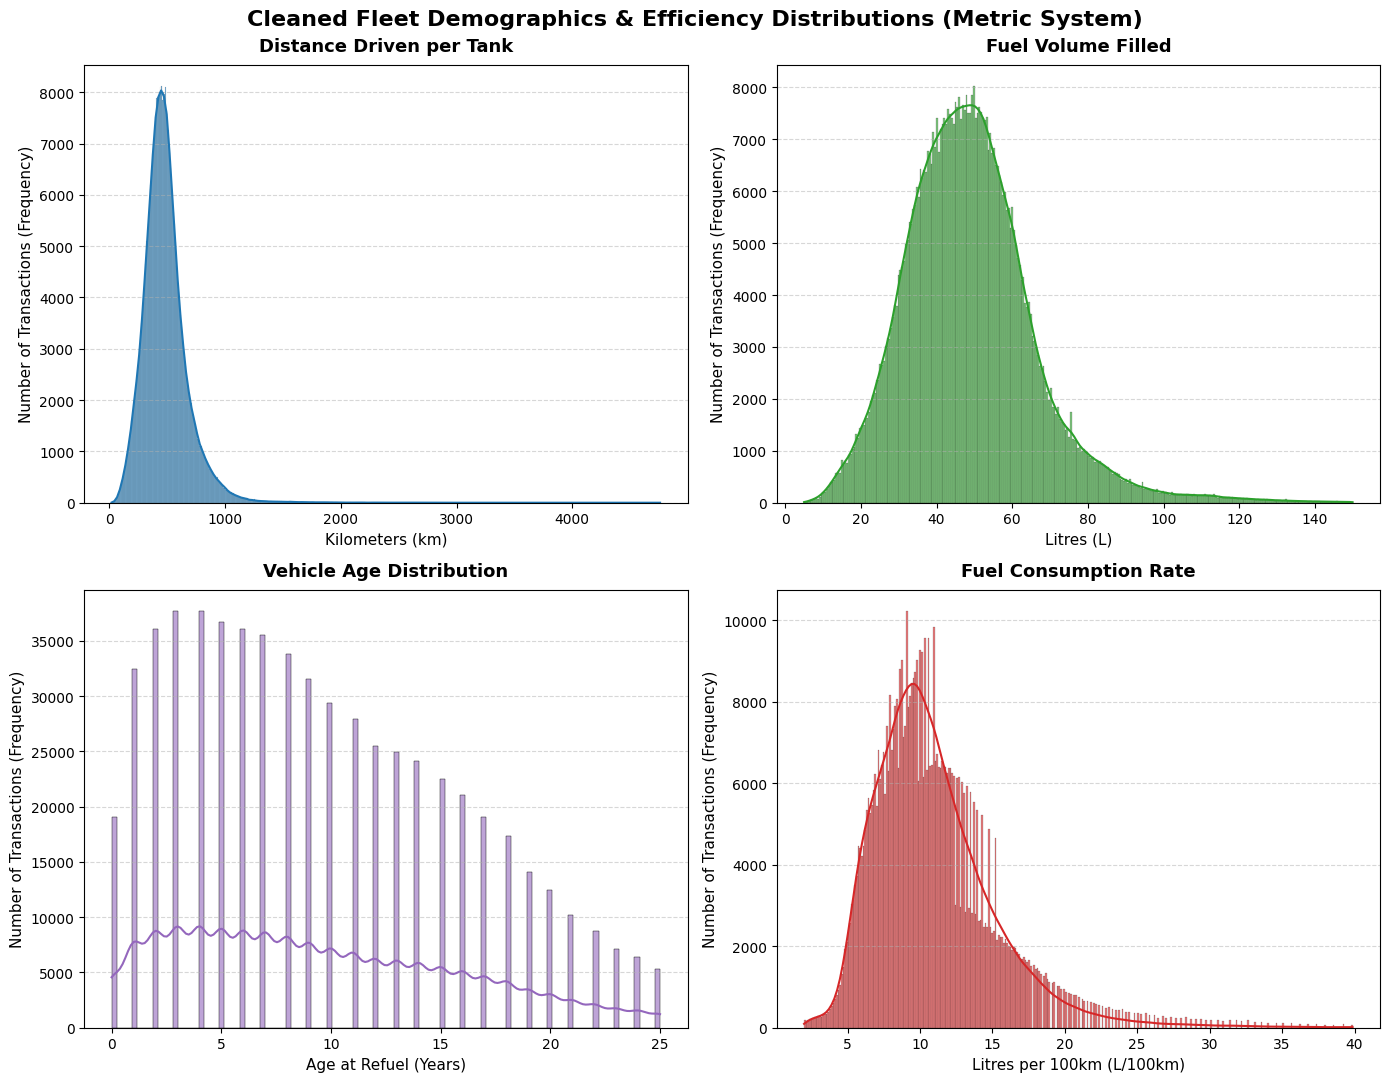

In [21]:

fig, axes = plt.subplots(2, 2, figsize=(14, 11))

metric_columns = ['km_driven', 'litres_filled', 'vehicle_age_at_refuel', 'litres_per_100km']
colors = ['#1f77b4', '#2ca02c', '#9467bd', '#d62728'] 
titles = ['Distance Driven per Tank', 'Fuel Volume Filled', 'Vehicle Age Distribution', 'Fuel Consumption Rate']
x_labels = ['Kilometers (km)', 'Litres (L)', 'Age at Refuel (Years)', 'Litres per 100km (L/100km)']

for ax, col, color, title, x_lbl in zip(axes.flatten(), metric_columns, colors, titles, x_labels):
    # Plot the histogram bar chart with a smooth trend curve
    sns.histplot(df_cleaned_master[col].dropna(), kde=True, ax=ax, color=color, alpha=0.6)
    
    # Customise titles and labels for an academic report look
    ax.set_title(title, fontsize=13, fontweight='bold', pad=10)
    ax.set_xlabel(x_lbl, fontsize=11)
    ax.set_ylabel('Number of Transactions (Frequency)', fontsize=11)
    ax.grid(axis='y', linestyle='--', alpha=0.5)

plt.suptitle('Cleaned Fleet Demographics & Efficiency Distributions (Metric System)', fontsize=16, fontweight='bold', y=0.98)
plt.tight_layout()
plt.show()


### Question 4.2


#### 4.2.1 Calculate the mean cost per litre grouped by currency

In [22]:
# 
df_cleaned_master['cost_per_litre'] = df_cleaned_master['cost_per_gallon'] / 3.78541

# 2. Filter data window exclusively for January 2022
jan_2022_df = df_cleaned_master[
    (df_cleaned_master['date_fueled'] >= '2022-01-01') & 
    (df_cleaned_master['date_fueled'] <= '2022-01-31')
]

# 3. Calculate the mean cost per litre grouped by currency
avg_fuel_price = jan_2022_df.groupby('currency')['cost_per_litre'].mean()
print("Average Cost Per Litre in Local Currency (Jan 2022):")
print(avg_fuel_price)

Average Cost Per Litre in Local Currency (Jan 2022):
currency
$       0.939447
CA$     1.769728
R      18.956828
£       1.486387
€       1.627828
Name: cost_per_litre, dtype: float64


#### 4.2.2

In [23]:

missed_logs_df = df_cleaned_master[df_cleaned_master['km_driven'] > 1200]

total_missed_count = len(missed_logs_df)
percentage_of_data = (total_missed_count / len(df_cleaned_master)) * 100

print(f"Estimated number of missed log anomalies: {total_missed_count}")
print(f"Percentage of total dataset: {percentage_of_data:.2f}%")

Estimated number of missed log anomalies: 3394
Percentage of total dataset: 0.55%


### 4.2.3

C:\Users\Wits student\AppData\Local\Temp\ipykernel_2768\2982683603.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=avg_dist_country.index, y=avg_dist_country.values, palette='magma')


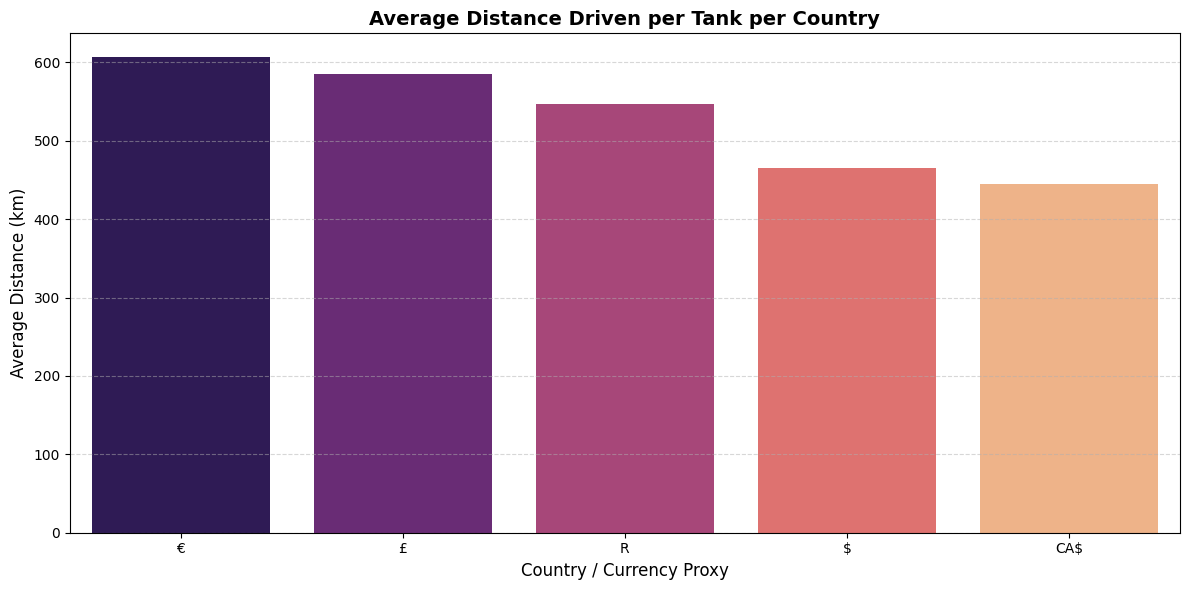

In [24]:


# Group by country/currency and find the average distance per tank
avg_dist_country = df_cleaned_master.groupby('currency')['km_driven'].mean().sort_values(ascending=False)

plt.figure(figsize=(12, 6))
sns.barplot(x=avg_dist_country.index, y=avg_dist_country.values, palette='magma')

plt.title('Average Distance Driven per Tank per Country', fontsize=14, fontweight='bold')
plt.xlabel('Country / Currency Proxy', fontsize=12)
plt.ylabel('Average Distance (km)', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


### 4.2.4

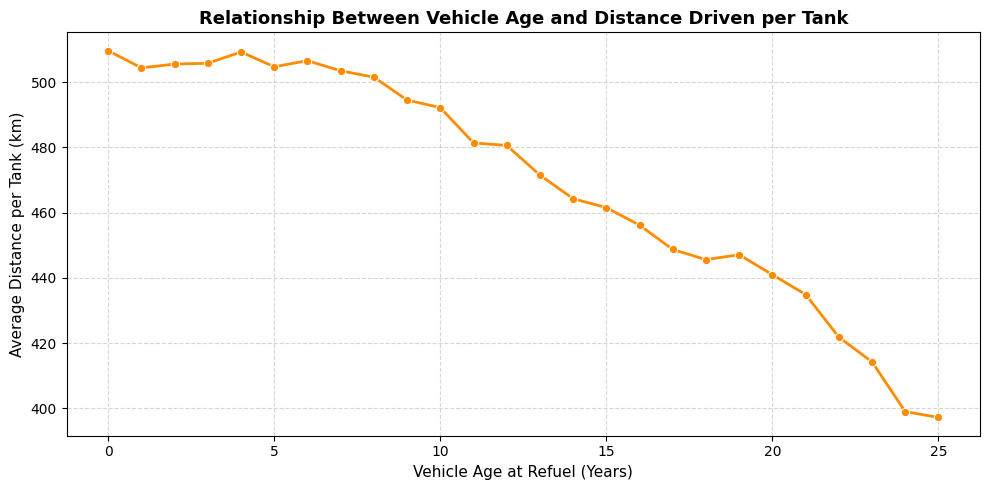

In [25]:


age_distance = df_cleaned_master.groupby('vehicle_age_at_refuel')['km_driven'].mean().reset_index()


plt.figure(figsize=(10, 5))
sns.lineplot(data=age_distance, x='vehicle_age_at_refuel', y='km_driven', marker='o', color='darkorange', linewidth=2)

plt.title('Relationship Between Vehicle Age and Distance Driven per Tank', fontsize=13, fontweight='bold')
plt.xlabel('Vehicle Age at Refuel (Years)', fontsize=11)
plt.ylabel('Average Distance per Tank (km)', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


#### 4.2.5

In [26]:

df_cleaned_master['make_model'] = df_cleaned_master['car_name'].astype(str) + " " + df_cleaned_master['model'].astype(str)


df_sa = df_cleaned_master[df_cleaned_master['currency'].isin(['R', 'ZAR'])].copy()


top_5_sa_vehicles = df_sa.groupby('make_model')['user_id'].nunique().sort_values(ascending=False).head(5).index.tolist()


df_top5_sa = df_sa[df_sa['make_model'].isin(top_5_sa_vehicles)]

sa_efficiency = df_top5_sa.groupby('make_model')['litres_per_100km'].agg(['count', 'mean', 'median', 'std']).round(2)
print("--- South African Top 5 Vehicles Fuel Efficiency Summary ---")
print(sa_efficiency)


--- South African Top 5 Vehicles Fuel Efficiency Summary ---
                   count   mean  median   std
make_model                                   
mitsubishi pajero    753  12.60   12.00  3.29
suzuki jimny         567   9.30    9.05  2.14
toyota fortuner      806  11.44   11.04  2.75
toyota hilux         943  11.78   11.04  3.61
volkswagen polo      589   7.63    7.26  2.85


#### 4.2.6

In [27]:
# 1. Create a grouping to find the average efficiency per vehicle per country
grouped = df_cleaned_master.groupby(['currency', 'make_model'])['litres_per_100km'].agg(['count', 'mean']).reset_index()

# 2. Filter out vehicles with low log frequencies (< 30 transactions) to preserve data integrity
valid_grouped = grouped[grouped['count'] >= 30]

# 3. Find the minimum 'mean' entry (most efficient) for each currency group
most_efficient_per_country = valid_grouped.loc[valid_grouped.groupby('currency')['mean'].idxmin()]

print("--- Most Fuel-Efficient Vehicles per Country ---")
print(most_efficient_per_country.to_string(index=False))


--- Most Fuel-Efficient Vehicles per Country ---
currency         make_model  count     mean
       $ toyota prius_prime    540 3.605770
     CA$ toyota prius_prime     49 3.635155
       R        toyota aygo     54 5.855606
       £      hyundai ioniq    111 4.479645
       €      hyundai ioniq     48 4.840848


#### 4.2.7

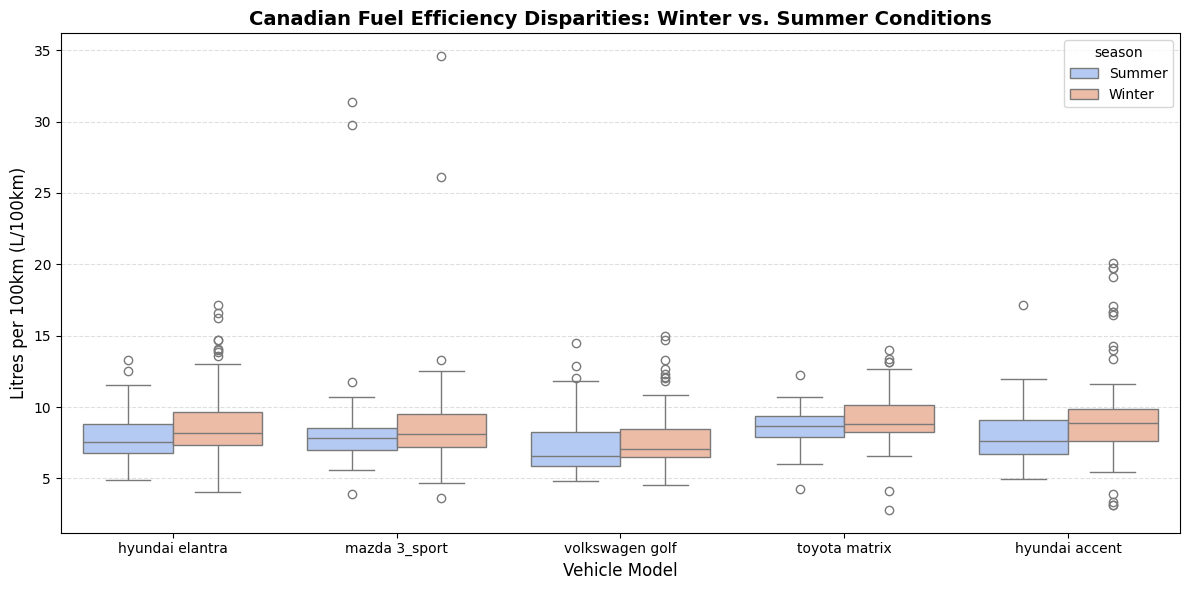

In [28]:

df_ca = df_cleaned_master[df_cleaned_master['currency'].isin(['CA$', 'CAD'])].copy()

df_ca['month'] = df_ca['date_fueled'].dt.month

def map_season(m):
    if m in [12, 1, 2]: return 'Winter'
    elif m in [6, 7, 8]: return 'Summer'
    else: return 'Transition'

df_ca['season'] = df_ca['month'].apply(map_season)
df_ca_seasonal = df_ca[df_ca['season'].isin(['Winter', 'Summer'])]

top_5_ca_vehicles = df_ca_seasonal['make_model'].value_counts().head(5).index
df_ca_top5_seasonal = df_ca_seasonal[df_ca_seasonal['make_model'].isin(top_5_ca_vehicles)]

plt.figure(figsize=(12, 6))
sns.boxplot(data=df_ca_top5_seasonal, x='make_model', y='litres_per_100km', hue='season', palette='coolwarm')

plt.title('Canadian Fuel Efficiency Disparities: Winter vs. Summer Conditions', fontsize=14, fontweight='bold')
plt.xlabel('Vehicle Model', fontsize=12)
plt.ylabel('Litres per 100km (L/100km)', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()


#### 4.2.8

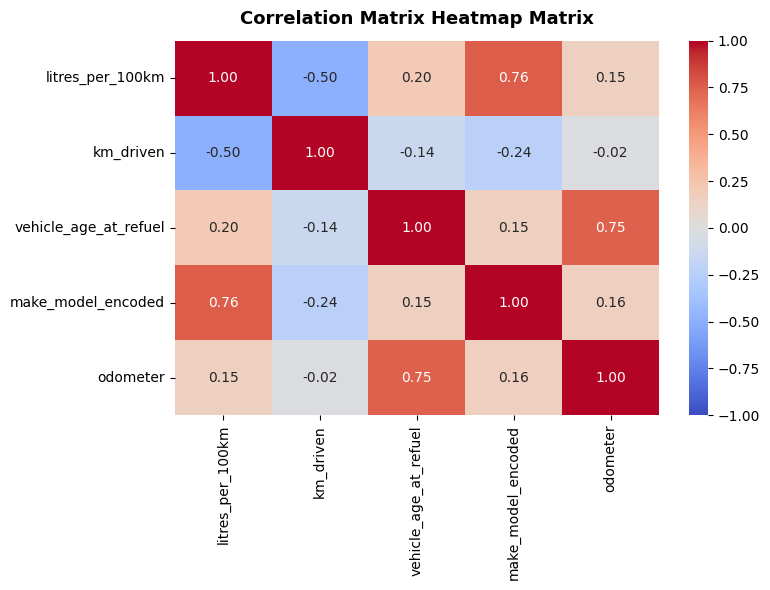

In [29]:

model_mapping = df_cleaned_master.groupby('make_model')['litres_per_100km'].mean()
df_cleaned_master['make_model_encoded'] = df_cleaned_master['make_model'].map(model_mapping)

correlation_features = ['litres_per_100km', 'km_driven', 'vehicle_age_at_refuel', 'make_model_encoded', 'odometer']
corr_matrix = df_cleaned_master[correlation_features].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", vmin=-1, vmax=1)
plt.title('Correlation Matrix Heatmap Matrix', fontsize=13, fontweight='bold', pad=12)
plt.tight_layout()
plt.show()


#### 4.2.9

In [30]:
from sklearn.ensemble import RandomForestRegressor

df_sample = df_cleaned_master.dropna(subset=correlation_features).sample(n=30000, random_state=42)

X = df_sample[['km_driven', 'vehicle_age_at_refuel', 'make_model_encoded', 'odometer']]
y = df_sample['litres_per_100km']


rf_model = RandomForestRegressor(n_estimators=50, max_depth=12, random_state=42, n_jobs=-1)
rf_model.fit(X, y)

importances = rf_model.feature_importances_
importance_df = pd.DataFrame({
    'Feature': X.columns,
    'Random_Forest_Importance': importances
}).sort_values(by='Random_Forest_Importance', ascending=False)

print("--- Random Forest Feature Importance Matrix ---")
print(importance_df.round(4).to_string(index=False))


--- Random Forest Feature Importance Matrix ---
              Feature  Random_Forest_Importance
   make_model_encoded                    0.7104
            km_driven                    0.2197
             odometer                    0.0414
vehicle_age_at_refuel                    0.0285


### Question 4.3

#### 4.3.1  Looking at South African entries only

In [31]:

df_sa = df_cleaned_master[df_cleaned_master['currency'].isin(['R', 'ZAR'])].copy()


#### 4.3.2

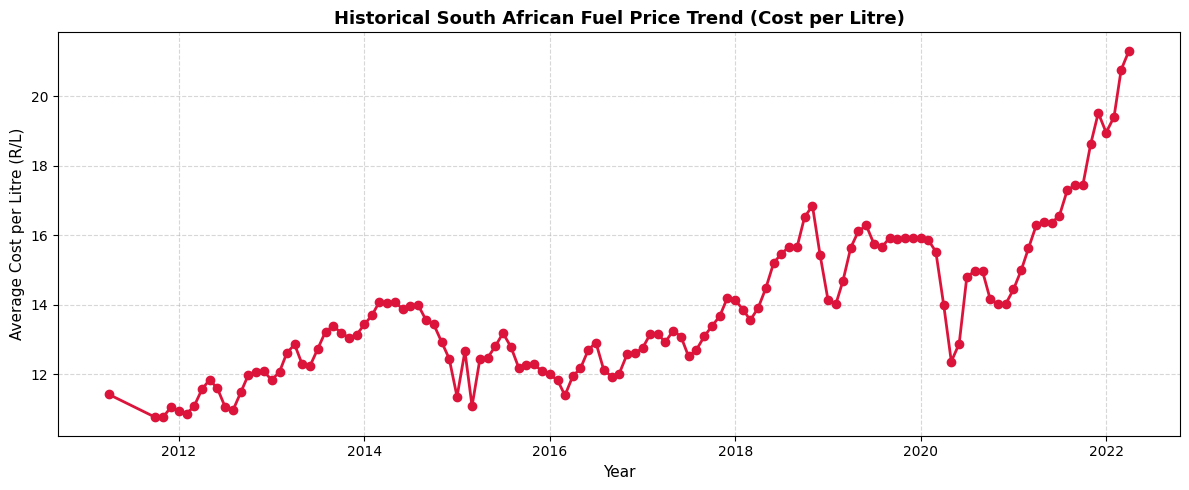

In [32]:
df_sa['cost_per_litre'] = df_sa['cost_per_gallon'] / 3.78541

# Group by month to see the macro price trend line
monthly_prices = df_sa.groupby(df_sa['date_fueled'].dt.to_period('M'))['cost_per_litre'].mean()

plt.figure(figsize=(12, 5))
plt.plot(monthly_prices.index.to_timestamp(), monthly_prices.values, marker='o', color='crimson', linewidth=2)

plt.title('Historical South African Fuel Price Trend (Cost per Litre)', fontsize=13, fontweight='bold')
plt.xlabel('Year', fontsize=11)
plt.ylabel('Average Cost per Litre (R/L)', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

#### 4.3.3

C:\Users\Wits student\AppData\Local\Temp\ipykernel_2768\3068737617.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=day_counts.index, y=day_counts.values, palette='Blues_d')


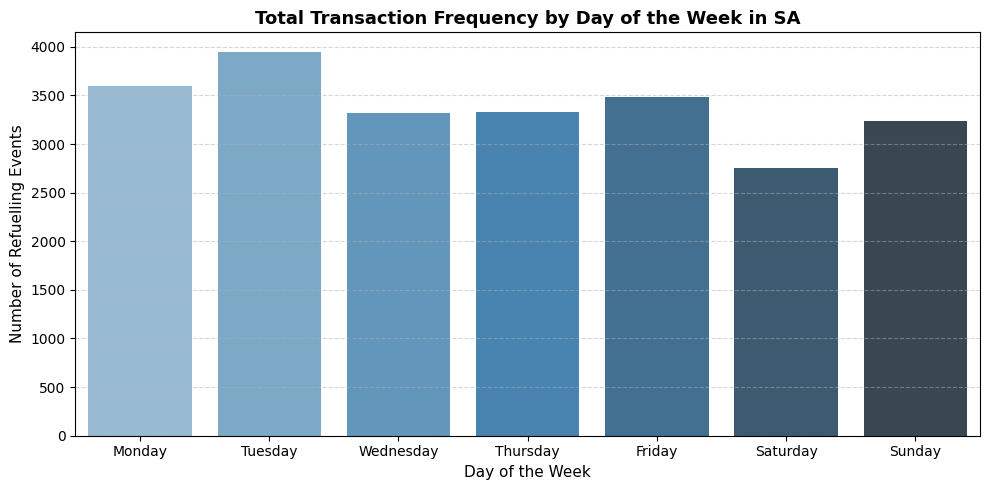

In [33]:

df_sa['day_of_week'] = df_sa['date_fueled'].dt.day_name()

day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
day_counts = df_sa['day_of_week'].value_counts().reindex(day_order)

plt.figure(figsize=(10, 5))
sns.barplot(x=day_counts.index, y=day_counts.values, palette='Blues_d')

plt.title('Total Transaction Frequency by Day of the Week in SA', fontsize=13, fontweight='bold')
plt.xlabel('Day of the Week', fontsize=11)
plt.ylabel('Number of Refuelling Events', fontsize=11)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


#### 4.3.4

In [34]:

df_sa['year'] = df_sa['date_fueled'].dt.year
df_sa['month'] = df_sa['date_fueled'].dt.month
df_sa['day'] = df_sa['date_fueled'].dt.day
df_sa['day_num'] = df_sa['date_fueled'].dt.weekday # Mon=0, Tue=1, Wed=2, etc.

# 2. Identify the first Tuesday (day_num == 1 and day <= 7)
# and the first Wednesday (day_num == 2 and day <= 7)
df_first_days = df_sa[
    ((df_sa['day_num'] == 1) & (df_sa['day'] <= 7)) | 
    ((df_sa['day_num'] == 2) & (df_sa['day'] <= 7))
].copy()


#### 4.3.5

In [35]:

monthly_avg = df_sa.groupby(['year', 'month'])['cost_per_litre'].mean().reset_index()
monthly_avg = monthly_avg.sort_values(['year', 'month']).reset_index(drop=True)

# Shift columns to calculate the price difference relative to the prior month
monthly_avg['prev_price'] = monthly_avg['cost_per_litre'].shift(1)
monthly_avg['price_change'] = np.where(
    monthly_avg['cost_per_litre'] > monthly_avg['prev_price'], 'Up', 'Down'
)

# Merge the price direction indicators back into filtered day table
df_first_days = df_first_days.merge(
    monthly_avg[['year', 'month', 'price_change']], 
    on=['year', 'month'], 
    how='left'
)


In [36]:

daily_activity = df_first_days.groupby(['year', 'month', 'date_fueled', 'day_of_week', 'price_change']).size().reset_index(name='daily_transaction_count')

behavior_summary = daily_activity.groupby(['day_of_week', 'price_change'])['daily_transaction_count'].mean().round(2)
print("--- Average Daily Refuelling Events on Price Adjustment Weeks ---")
print(behavior_summary)


--- Average Daily Refuelling Events on Price Adjustment Weeks ---
day_of_week  price_change
Tuesday      Down             5.17
             Up              14.48
Wednesday    Down             7.02
             Up               5.56
Name: daily_transaction_count, dtype: float64


####  4.3.6 and 4.3.7

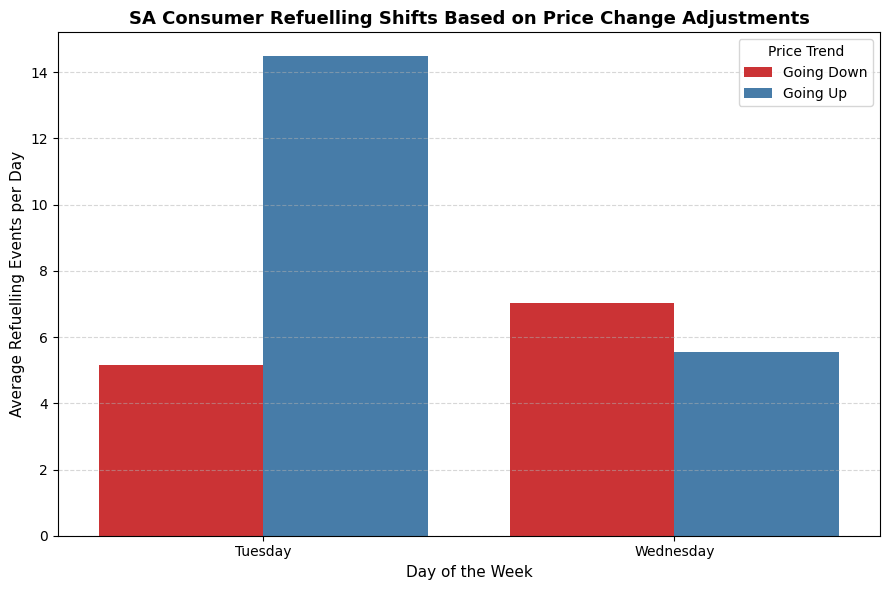

In [37]:

plot_data = pd.DataFrame([
    {'Day': 'Tuesday', 'Price Trend': 'Going Down', 'Average Transactions': 5.17},
    {'Day': 'Tuesday', 'Price Trend': 'Going Up', 'Average Transactions': 14.48},
    {'Day': 'Wednesday', 'Price Trend': 'Going Down', 'Average Transactions': 7.02},
    {'Day': 'Wednesday', 'Price Trend': 'Going Up', 'Average Transactions': 5.56}
])

# Create a grouped bar chart
plt.figure(figsize=(9, 6))
sns.barplot(data=plot_data, x='Day', y='Average Transactions', hue='Price Trend', palette='Set1')

plt.title('SA Consumer Refuelling Shifts Based on Price Change Adjustments', fontsize=13, fontweight='bold')
plt.xlabel('Day of the Week', fontsize=11)
plt.ylabel('Average Refuelling Events per Day', fontsize=11)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()
